# Курсовая работа: Методы машинного обучения
**Тема:** Выявление сообществ в сетях с использованием алгоритмов кластеризации  
**Выполнил:** студент группы 231-329 Горский Владислав

In [25]:
import community as community_louvain
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

from collections import Counter
from scipy import stats
from scipy.sparse import csr_matrix
from sklearn.cluster import AgglomerativeClustering, SpectralClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, adjusted_rand_score, classification_report, confusion_matrix, f1_score, normalized_mutual_info_score, precision_score, recall_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42          # единый seed для всего ноутбука
np.random.seed(RANDOM_STATE)

Был выбран датасет [email-Eu-core network](https://snap.stanford.edu/data/email-Eu-core.html), в котором представлен ориентированный граф, отражающий общение 1 005 сотрудников из 42 разных отделов исследовательского института по электронной почте. В отличие от более полного датасета [EU email communication network](https://snap.stanford.edu/data/email-EuAll.html), данный датасет строго ограничен перепиской сотрудников внутри института.

Как следствие, задачей курсовой работы является кластеризация представленных узлов (сотрудников института) по сообществам (отделам) и последующей проверкой точности кластеризации с помощью ground-truth.

In [26]:
edges = pd.read_csv('./data/email-Eu-core.txt', sep=' ', header=None, names=['source', 'target'])
G = nx.from_pandas_edgelist(edges, 'source', 'target')

labels = pd.read_csv('./data/email-Eu-core-department-labels.txt', sep=' ', header=None, names=['node', 'community'])
ground_truth = dict(zip(labels['node'], labels['community']))

print(f"Загружен граф: {G.number_of_nodes()} узлов, {G.number_of_edges()} рёбер")
print(f"Ground truth: {len(set(ground_truth.keys()))} сотрудников, {len(set(ground_truth.values()))} отделов")

Загружен граф: 1005 узлов, 16706 рёбер
Ground truth: 1005 сотрудников, 42 отделов


In [27]:
print("=== Предварительный анализ ===")
print(f"Тип графа: {'ориентированный' if G.is_directed() else 'неориентированный'}")
print(f"Взвешенный: {nx.is_weighted(G)}")
print(f"Количество компонент связности: {nx.number_connected_components(G)}")

isolated = list(nx.isolates(G))
print(f"Изолированные узлы: {len(isolated)}")

# Распределение степеней
degrees = [d for _, d in G.degree()]
print(f"Средняя степень: {np.mean(degrees):.2f}")
print(f"Медиана степени: {np.median(degrees):.1f}")
print(f"Максимальная степень: {np.max(degrees)}")

=== Предварительный анализ ===
Тип графа: неориентированный
Взвешенный: False
Количество компонент связности: 20
Изолированные узлы: 0
Средняя степень: 33.25
Медиана степени: 23.0
Максимальная степень: 347


В графовых данных "пропусками" являются узлы без рёбер и узлы, чья единственная связь — петля (сотрудник писал только сам себе). Такие узлы не несут информации о сообществах. Поэтому удаляем 642 петли, 19 возникших после этого изолятов и 2 узла, оставшихся в одиночку в своих отделах (№18, №33). Атрибутов у узлов в датасете нет — единственный источник информации о целевой переменной (отделе) — топология графа, поэтому признаки конструируются из структуры.

In [28]:
# ========== ОЧИСТКА (идемпотентная: граф и метки пересоздаются из исходников) ==========
G = nx.from_pandas_edgelist(edges, 'source', 'target')          # пересоздаём, а не мутируем
ground_truth = dict(zip(labels['node'], labels['community']))   # и метки тоже

n0, m0 = G.number_of_nodes(), G.number_of_edges()
c0 = nx.number_connected_components(G)

n_selfloops = nx.number_of_selfloops(G)
G.remove_edges_from(nx.selfloop_edges(G))

isolated = sorted(nx.isolates(G))                                # изоляты ПОСЛЕ снятия петель
G.remove_nodes_from(isolated)
ground_truth = {n: c for n, c in ground_truth.items() if n in G}

counts = Counter(ground_truth.values())
drop_depts = {d for d, c in counts.items() if c < 2}
drop_nodes = sorted(n for n, c in ground_truth.items() if c in drop_depts)
G.remove_nodes_from(drop_nodes)
ground_truth = {n: c for n, c in ground_truth.items() if c not in drop_depts}

print(f"Было: {n0} узлов, {m0} рёбер, компонент: {c0}")
print(f"Удалено self-loops: {n_selfloops}")
print(f"Удалено изолятов (узлы, писавшие только сами себе): {len(isolated)}")
print(f"Удалено департаментов с <2 узлами: {sorted(drop_depts)} (узлы {drop_nodes})")
print(f"Стало: {G.number_of_nodes()} узлов, {G.number_of_edges()} рёбер, компонент: {nx.number_connected_components(G)}")

Было: 1005 узлов, 16706 рёбер, компонент: 20
Удалено self-loops: 642
Удалено изолятов (узлы, писавшие только сами себе): 19
Удалено департаментов с <2 узлами: [18, 33] (узлы [767, 870])
Стало: 984 узлов, 16055 рёбер, компонент: 1


In [29]:
# Распределение степеней
degrees = [d for _, d in G.degree()]
print(f"Средняя степень: {np.mean(degrees):.2f}")
print(f"Медиана степени: {np.median(degrees):.1f}")
print(f"Максимальная степень: {np.max(degrees)}")

Средняя степень: 32.63
Медиана степени: 22.0
Максимальная степень: 345


In [30]:
# В Email-Eu-Core атрибутов узлов нет — только структура.
# Для демонстрации создадим структурные признаки, которые понадобятся позже для классификации.
node_features = pd.DataFrame(index=list(G.nodes()))
node_features['degree'] = pd.Series(dict(G.degree()), index=node_features.index)
node_features['clustering'] = pd.Series(nx.clustering(G), index=node_features.index)
node_features['betweenness'] = pd.Series(nx.betweenness_centrality(G), index=node_features.index)
node_features['closeness'] = pd.Series(nx.closeness_centrality(G), index=node_features.index)
node_features['pagerank'] = pd.Series(nx.pagerank(G), index=node_features.index)
node_features['kcore'] = pd.Series(nx.core_number(G), index=node_features.index)
node_features['triangles'] = pd.Series(nx.triangles(G), index=node_features.index)
node_features['avg_nbr_deg'] = pd.Series(nx.average_neighbor_degree(G), index=node_features.index)
node_features['eigenvector'] = pd.Series(nx.eigenvector_centrality(G, max_iter=1000), index=node_features.index)

if node_features.isna().any().any():   # явная проверка вместо молчаливых NaN
    raise ValueError('Не для всех узлов посчитаны признаки')
print(node_features.describe())

           degree  clustering  betweenness   closeness    pagerank  \
count  984.000000  984.000000   984.000000  984.000000  984.000000   
mean    32.632114    0.406509     0.001615    0.394616    0.001016   
std     37.038744    0.247471     0.004620    0.054723    0.000969   
min      1.000000    0.000000     0.000000    0.212955    0.000175   
25%      7.000000    0.272560     0.000008    0.352709    0.000337   
50%     22.000000    0.384526     0.000204    0.397815    0.000755   
75%     45.000000    0.526681     0.001322    0.433278    0.001339   
max    345.000000    1.000000     0.091012    0.585119    0.009446   

            kcore    triangles  avg_nbr_deg  eigenvector  
count  984.000000   984.000000   984.000000   984.000000  
mean    17.417683   321.496951    74.911945     0.020143  
std     11.122610   586.358499    30.156310     0.024721  
min      1.000000     0.000000     4.000000     0.000001  
25%      6.000000     9.750000    58.447218     0.003470  
50%     18.0000

Все пять признаков — шкала отношений, но диапазоны различаются на пять порядков (degree до 345 против pagerank ~0.01), поэтому для моделей, чувствительных к масштабу (LR, KNN), применяется стандартизация внутри Pipeline. Метки кластеров — номинальная шкала, поэтому в признаки они включаются через one-hot, а не как числа.

=== Кластеризация ===
Louvain: модульность = 0.4151, сообществ = 7
Greedy Modularity: сообществ = 8
Spectral: кластеров = 40
Agglomerative: кластеров = 40
Louvain: NMI = 0.5375, ARI = 0.2392
Greedy Modularity: NMI = 0.4281, ARI = 0.1543
Spectral: NMI = 0.5342, ARI = 0.1182
Agglomerative: NMI = 0.2633, ARI = 0.0279


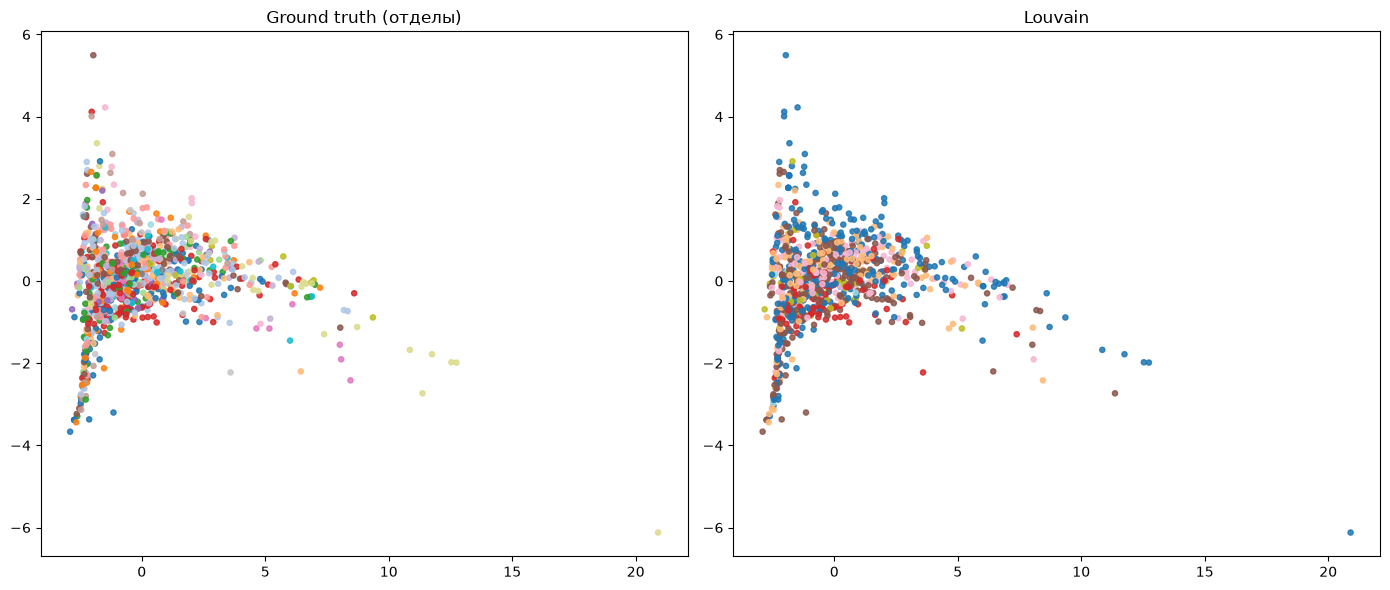

In [31]:
print("=== Кластеризация ===")

node_to_idx = {n: i for i, n in enumerate(G.nodes())}

def labels_in_node_order(communities):
    labels_arr = np.full(len(node_to_idx), -1, dtype=int)
    for cid, comm in enumerate(communities):
        for node in comm:
            labels_arr[node_to_idx[node]] = cid
    if (labels_arr < 0).any():
        raise ValueError('Не все узлы покрыты сообществами')
    return labels_arr

# 1. Louvain
partition = community_louvain.best_partition(G, random_state=RANDOM_STATE)
louvain_labels = np.array([partition[n] for n in G.nodes()])
print(f"Louvain: модульность = {community_louvain.modularity(partition, G):.4f}, сообществ = {len(set(louvain_labels))}")

# 2. Greedy Modularity (CNM)
gm_communities = list(nx.community.greedy_modularity_communities(G))
gm_labels = labels_in_node_order(gm_communities)
print(f"Greedy Modularity: сообществ = {len(gm_communities)}")

# 3. Spectral
n_clusters = len(set(ground_truth.values()))
adj_sparse = csr_matrix(nx.to_scipy_sparse_array(G, nodelist=list(G.nodes())))
spectral = SpectralClustering(n_clusters=n_clusters, affinity='precomputed', assign_labels='kmeans', random_state=RANDOM_STATE)
spectral_labels = spectral.fit_predict(adj_sparse)
print(f"Spectral: кластеров = {n_clusters}")

# 4. Agglomerative на стандартизованных признаках
X_scaled = StandardScaler().fit_transform(node_features)
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)
print(f"Agglomerative: кластеров = {n_clusters}")

# Оценка
gt_labels = np.array([ground_truth[n] for n in G.nodes()])
for name, lab in [('Louvain', louvain_labels), ('Greedy Modularity', gm_labels), ('Spectral', spectral_labels), ('Agglomerative', agg_labels)]:
    print(f"{name}: NMI = {normalized_mutual_info_score(gt_labels, lab):.4f}, ARI = {adjusted_rand_score(gt_labels, lab):.4f}")

xy = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(StandardScaler().fit_transform(node_features))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (t, c) in zip(axes, [('Ground truth (отделы)', gt_labels), ('Louvain', louvain_labels)]):
    ax.scatter(xy[:, 0], xy[:, 1], c=c, cmap='tab20', s=14, alpha=0.85)
    ax.set_title(t)
plt.tight_layout()
plt.show()

Метрики выбраны до моделирования. 

Для кластеризации: модульность (качество разбиения без учителя), NMI и ARI — потому что они инвариантны к перестановке номеров кластеров, в отличие от accuracy. 

Для классификации: f1-macro — из-за сильного дисбаланса 40 классов (от 5 до ~250 узлов); accuracy и f1-weighted приводятся справочно. Разделение — случайное стратифицированное 70/30: временной порядок в агрегированном графе отсутствует, а stratify гарантирует попадание малых классов в обе выборки

In [32]:
# Задача: предсказать метку департамента по структурным признакам узла.
MIN_CLASS_SIZE = 5   # классы меньшего размера исключаются: при 70/30 это гарантирует
                     # >= 3 объекта в train, т.е. валидные фолды cv=3 без предупреждений

y_raw = np.array([ground_truth[n] for n in node_features.index])  # порядок равен строкам node_features
counts = Counter(y_raw)
drop_classes = {c for c, cnt in counts.items() if cnt < MIN_CLASS_SIZE}
keep_mask = np.array([c not in drop_classes for c in y_raw])      # единая маска для всех вариантов X
X = node_features.values[keep_mask]
y = y_raw[keep_mask]                                              # только int, без 'rare'

print(f"Классов всего: {len(counts)}; удалено редких (<{MIN_CLASS_SIZE}): {len(drop_classes)} классов, {int((~keep_mask).sum())} узлов")

idx_all = np.arange(len(y))
idx_train, idx_test = train_test_split(idx_all, test_size=0.3, stratify=y,
                                       random_state=RANDOM_STATE)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

# StandardScaler внутри Pipeline обучается только на train — без утечки
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'K-Nearest Neighbors': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"\n--- {name} ---")
    print(classification_report(y_test, model.predict(X_test), zero_division=0))

Классов всего: 40; удалено редких (<5): 5 классов, 16 узлов

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        15
           1       0.17      0.11      0.13        19
           2       0.00      0.00      0.00         3
           3       0.00      0.00      0.00         4
           4       0.15      0.59      0.24        32
           5       0.00      0.00      0.00         5
           6       0.00      0.00      0.00         8
           7       0.27      0.20      0.23        15
           8       0.00      0.00      0.00         6
           9       0.00      0.00      0.00         9
          10       0.00      0.00      0.00        12
          11       0.00      0.00      0.00         9
          13       0.00      0.00      0.00         8
          14       0.26      0.67      0.38        27
          15       0.05      0.06      0.05        16
          16       0.00      0.00      0.00   

In [33]:
# Выбираем Random Forest как обычно устойчивую модель для табличных признаков
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf = RandomForestClassifier(random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)  # воспроизводимые фолды
grid = GridSearchCV(rf, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Лучшие гиперпараметры:", grid.best_params_)
print("Лучший CV-score (f1_macro):", grid.best_score_)  

best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
print("\nРезультат на тесте:")
print(classification_report(y_test, y_pred_best, zero_division=0))

Fitting 3 folds for each of 18 candidates, totalling 54 fits


Лучшие гиперпараметры: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Лучший CV-score (f1_macro): 0.1243443447487883

Результат на тесте:
              precision    recall  f1-score   support

           0       0.12      0.07      0.09        15
           1       0.42      0.42      0.42        19
           2       0.50      0.33      0.40         3
           3       0.00      0.00      0.00         4
           4       0.18      0.25      0.21        32
           5       0.33      0.20      0.25         5
           6       0.00      0.00      0.00         8
           7       0.31      0.33      0.32        15
           8       0.33      0.17      0.22         6
           9       0.17      0.11      0.13         9
          10       0.27      0.33      0.30        12
          11       0.25      0.22      0.24         9
          13       0.00      0.00      0.00         8
          14       0.40      0.59      0.48        27
          15       0.15      0.19  

=== Сравнение на одном и том же тестовом наборе ===
Исходные признаки: f1_macro = 0.1717
Расширенные признаки: f1_macro = 0.4259


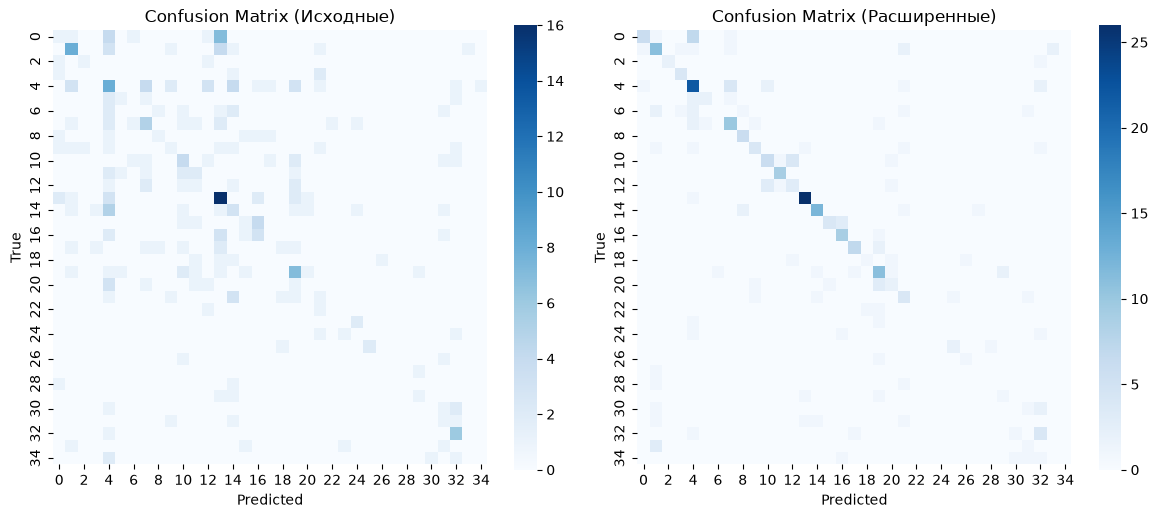

In [34]:
cluster_codes = pd.DataFrame({'louvain': louvain_labels, 'spectral': spectral_labels}, index=node_features.index).astype(str)
cluster_onehot = pd.get_dummies(cluster_codes, prefix=['lv', 'sp'])

node_features_enhanced = pd.concat([node_features, cluster_onehot], axis=1)
X_enh = node_features_enhanced.values[keep_mask]
X_train_enh, X_test_enh = X_enh[idx_train], X_enh[idx_test]

# Обучим лучшую модель на расширенных признаках
best_rf_enh = RandomForestClassifier(**grid.best_params_, random_state=RANDOM_STATE)
best_rf_enh.fit(X_train_enh, y_train)
y_pred_enh = best_rf_enh.predict(X_test_enh)

print("=== Сравнение на одном и том же тестовом наборе ===")
for name, y_pred in [('Исходные признаки', y_pred_best), ('Расширенные признаки', y_pred_enh)]:
    print(f"{name}: f1_macro = {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))       # один y_test для обеих матриц
for ax, (name, y_pred) in zip(axes, [('Исходные', y_pred_best), ('Расширенные', y_pred_enh)]):
    sns.heatmap(confusion_matrix(y_test, y_pred), cmap='Blues', square=True, ax=ax)
    ax.set_title(f'Confusion Matrix ({name})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.show()

In [35]:
importances = pd.Series(best_rf_enh.feature_importances_, index=node_features_enhanced.columns)
print(importances.sort_values(ascending=False).head(12).round(4))

avg_nbr_deg    0.0790
closeness      0.0695
pagerank       0.0694
eigenvector    0.0672
clustering     0.0638
triangles      0.0608
betweenness    0.0525
degree         0.0524
kcore          0.0496
lv_3           0.0449
lv_2           0.0411
lv_0           0.0282
dtype: float64


In [36]:
def row(name, y_pred):
    return {'model': name,
            'accuracy': accuracy_score(y_test, y_pred),
            'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
            'f1_weighted': f1_score(y_test, y_pred, average='weighted', zero_division=0),
            'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
            'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0)}

summary = pd.DataFrame([*(row(n, m.predict(X_test)) for n, m in models.items()),
                        row('RF (GridSearch)', y_pred_best),
                        row('RF + кластерные признаки', y_pred_enh)]).set_index('model').round(3)
print(summary)

                          accuracy  f1_macro  f1_weighted  precision_macro  \
model                                                                        
Logistic Regression          0.182     0.062        0.115            0.075   
Gradient Boosting            0.199     0.095        0.169            0.090   
Random Forest                0.251     0.162        0.226            0.159   
K-Nearest Neighbors          0.168     0.084        0.148            0.085   
RF (GridSearch)              0.251     0.172        0.227            0.178   
RF + кластерные признаки     0.581     0.426        0.554            0.431   

                          recall_macro  
model                                   
Logistic Regression              0.082  
Gradient Boosting                0.107  
Random Forest                    0.177  
K-Nearest Neighbors              0.096  
RF (GridSearch)                  0.180  
RF + кластерные признаки         0.441  
